In [1]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path().resolve().parent.parent / "data" / "aprobados-negados"
data_file = "merged_df.csv"

file_path = DATA_DIR / data_file

df = pd.read_csv(file_path, sep=";")
df.head()

,Unnamed: 0,n.credito,cartera,plazo,vinculacion,v.cuota,v.prestamo,s.capital,s.intereses,aportes,...,curtotalingresos,curtotalegresos,intestrato,actualización,default,puntaje_data,grupo_dptmto,grupo_ciudad,grupo_edad,grupo_actividadeco
0,0,003-002-0125852-7,consumo_sin_libranza,1827,8103,356849.0,15000000.0,12923538.0,123855,7741255,...,4597000.0,1500000.0,5.0,1.0,0.0,795.0,3.0,1.0,3.0,4.0
1,1,004-002-0068475-5,consumo_sin_libranza,1826,1434,2650409.0,100460000.0,31911361.0,263265,4601706,...,4597000.0,650000.0,5.0,1.0,0.0,836.0,3.0,5.0,3.0,4.0
2,2,003-002-0122592-9,consumo_sin_libranza,1826,573,791482.0,30000000.0,23844684.0,261477,530431,...,4400000.0,2000000.0,4.0,0.0,1.0,709.0,3.0,7.0,2.0,4.0
3,3,006-002-0023879-0,consumo_sin_libranza,2922,1902,2860501.0,176000000.0,113842595.0,1008570,3023534,...,22020000.0,1500000.0,4.0,1.0,0.0,733.0,3.0,6.0,3.0,1.0
4,4,006-002-0026159-4,consumo_sin_libranza,2557,1902,987637.0,50300000.0,38521256.0,317167,1023082,...,22020000.0,1500000.0,4.0,1.0,0.0,695.0,3.0,6.0,3.0,1.0


In [2]:
df = df.drop(columns=["Unnamed: 0"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12861 entries, 0 to 12860
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   n.credito           12861 non-null  object 
 1   cartera             12861 non-null  object 
 2   plazo               12861 non-null  int64  
 3   vinculacion         12861 non-null  int64  
 4   v.cuota             12861 non-null  float64
 5   v.prestamo          12861 non-null  float64
 6   s.capital           12861 non-null  float64
 7   s.intereses         12861 non-null  int64  
 8   aportes             12861 non-null  int64  
 9   morosidad           12861 non-null  int64  
 10  garantias           12861 non-null  int64  
 11  valorgarantia       12861 non-null  int64  
 12  reestr              12861 non-null  int64  
 13  ctasahorros         12861 non-null  object 
 14  edad                12861 non-null  float64
 15  tipoasociado        12861 non-null  int64  
 16  acti

In [3]:
df = df.rename(columns={"actualización": "actualizacion"})
df = df.drop(columns=[
        "morosidad",
        #"cartera",
        "grupo_dptmto",
        "grupo_ciudad",
        "grupo_edad",
        "grupo_actividadeco",
        "actualizacion",
        "s.intereses",
        "estado_cliente",
        "reestr"
    ], axis=1,)

df.columns = df.columns.str.replace(".", "_", regex=False)
df.columns = df.columns.str.replace(":", "_", regex=False)
df.columns = df.columns.str.replace(" ", "_", regex=False)
df.set_index("n_credito", inplace=True)
df.head()

,cartera,plazo,vinculacion,v_cuota,v_prestamo,s_capital,aportes,garantias,valorgarantia,ctasahorros,...,tipoasociado,actividadeconomica,departamento,ciudad,sexo,curtotalingresos,curtotalegresos,intestrato,default,puntaje_data
n_credito,,,,,,,,,,,,,,,,,,,,,
003-002-0125852-7,consumo_sin_libranza,1827,8103,356849.0,15000000.0,12923538.0,7741255,1,7741255,33042953.0,...,1,asalariados,antioquia,bolivariana,0.0,4597000.0,1500000.0,5.0,0.0,795.0
004-002-0068475-5,consumo_sin_libranza,1826,1434,2650409.0,100460000.0,31911361.0,4601706,1,4601706,3791115.0,...,1,asalariados,antioquia,envigado,0.0,4597000.0,650000.0,5.0,0.0,836.0
003-002-0122592-9,consumo_sin_libranza,1826,573,791482.0,30000000.0,23844684.0,530431,1,530431,94435.0,...,1,asalariados,antioquia,medellin,0.0,4400000.0,2000000.0,4.0,1.0,709.0
006-002-0023879-0,consumo_sin_libranza,2922,1902,2860501.0,176000000.0,113842595.0,3023534,2,320385440,54841.0,...,1,educacion_basica_secundaria,antioquia,rionegro,0.0,22020000.0,1500000.0,4.0,0.0,733.0
006-002-0026159-4,consumo_sin_libranza,2557,1902,987637.0,50300000.0,38521256.0,1023082,2,320385440,54841.0,...,1,educacion_basica_secundaria,antioquia,rionegro,0.0,22020000.0,1500000.0,4.0,0.0,695.0


In [4]:
df = df.dropna(subset=['default'])

In [5]:
correlations = df.select_dtypes(include="number").corr(method='spearman')

# identificar las variables altamente correlacionadas
highly_correlated = set()
for i in range(len(correlations.columns)):
    for j in range(i):
        if abs(correlations.iloc[i, j]) > 0.8:
            colname = correlations.columns[i]
            highly_correlated.add(colname)
            highly_correlated.add(correlations.columns[j])
            print(f"Las variables {colname} y {correlations.columns[j]} están altamente correlacionadas.")

Las variables v_prestamo y v_cuota están altamente correlacionadas.
Las variables s_capital y v_cuota están altamente correlacionadas.
Las variables s_capital y v_prestamo están altamente correlacionadas.
Las variables valorgarantia y aportes están altamente correlacionadas.


In [6]:
# Analizar el aporte de información de las variables altamente correlacionadas con respecto a la variable objetivo 'default'

vars_to_analyze = list(highly_correlated)

for var in vars_to_analyze:
    correlation_with_target = df[var].corr(df['default'], method='spearman')
    print(f"La variable {var} tiene una correlación de {correlation_with_target:.4f} con la variable objetivo 'default'.")

La variable aportes tiene una correlación de -0.2137 con la variable objetivo 'default'.
La variable valorgarantia tiene una correlación de -0.2451 con la variable objetivo 'default'.
La variable s_capital tiene una correlación de -0.0338 con la variable objetivo 'default'.
La variable v_cuota tiene una correlación de -0.1309 con la variable objetivo 'default'.
La variable v_prestamo tiene una correlación de -0.0848 con la variable objetivo 'default'.


In [7]:
# Eliminar las 3 variables altamente correlacionadas del DataFrame con menor correlación con la variable objetivo 'default'

df = df.drop(columns=['valorgarantia', 'v_prestamo', 's_capital'], axis=1)

In [8]:
# =====================================================================
# MODIFICACIÓN OOT: Exclusión de Inmaduros + Partición OOT
# =====================================================================

# 1. Extraer el identificador secuencial de originación del crédito
df['credit_id_seq'] = df.index.to_series().apply(
    lambda x: int(str(x).split('-')[2]) if isinstance(x, str) and len(str(x).split('-')) >= 3 else None
)

# 2. Ordenar cronológicamente
df = df.sort_values(by='credit_id_seq').reset_index(drop=True)

# 3. EXCLUSIÓN DE COSECHAS INMADURAS (Descartar el 15% más reciente)
limite_madurez = int(len(df) * 0.85)
df_mature = df.iloc[:limite_madurez].copy()

print(f"Total histórico: {len(df)}")
print(f"Créditos excluidos por inmadurez: {len(df) - len(df_mature)}")
print(f"Total créditos maduros a modelar: {len(df_mature)}")

# 4. Separar features y variable objetivo del dataset maduro
X = df_mature.drop(["default", "credit_id_seq"], axis=1)
y = df_mature["default"]

# Ajustar tipo de variables categóricas
categorical_features = X.select_dtypes(include="object").columns.to_list()
X[categorical_features] = X[categorical_features].astype("category")

# 5. Partición OOT (80% Train, 20% Test sobre la cartera madura)
train_size = int(len(df_mature) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]
y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print(f"\\nTasa default TRAIN: {y_train.mean():.2%}")
print(f"Tasa default TEST: {y_test.mean():.2%}")

Total histórico: 12857
Créditos excluidos por inmadurez: 1929
Total créditos maduros a modelar: 10928
\nTasa default TRAIN: 21.71%
Tasa default TEST: 13.31%


In [9]:
y_train.value_counts(normalize=True)

default
0.0    0.782887
1.0    0.217113
Name: proportion, dtype: float64

In [10]:
y_test.value_counts(normalize=True)

default
0.0    0.86688
1.0    0.13312
Name: proportion, dtype: float64

In [11]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8742 entries, 0 to 8741
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   cartera             8742 non-null   category
 1   plazo               8742 non-null   int64   
 2   vinculacion         8742 non-null   int64   
 3   v_cuota             8742 non-null   float64 
 4   aportes             8742 non-null   int64   
 5   garantias           8742 non-null   int64   
 6   ctasahorros         8742 non-null   category
 7   edad                8742 non-null   float64 
 8   tipoasociado        8742 non-null   int64   
 9   actividadeconomica  8736 non-null   category
 10  departamento        8742 non-null   category
 11  ciudad              8736 non-null   category
 12  sexo                8742 non-null   float64 
 13  curtotalingresos    8742 non-null   float64 
 14  curtotalegresos     8742 non-null   float64 
 15  intestrato          8742 non-null   fl

In [12]:
categorical_features

['cartera', 'ctasahorros', 'actividadeconomica', 'departamento', 'ciudad']

In [13]:
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    verbose=0,
    seed=1,
    feature_fraction_seed=1,
    bagging_seed=1,
    drop_seed=1,
    force_col_wise=True,
    deterministic=True,
    )


model.fit(
    X_train, 
    y_train,
)
    
train_score = f1_score(y_train, model.predict(X_train))
test_score = f1_score(y_test, model.predict(X_test))
print(f"Train score: {train_score:.2f}")
print(f"Test score: {test_score:.2f}")

Train score: 0.88
Test score: 0.59


In [14]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_lgb = {
    'n_estimators': randint(50, 400),
    'max_depth': randint(3, 8),
    'num_leaves': randint(20, 100),
    'learning_rate': loguniform(0.01, 0.3),
    'min_child_samples': randint(10, 50),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-3, 10)
}

model = LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    verbose=0,
    seed=1,
    feature_fraction_seed=1,
    bagging_seed=1,
    drop_seed=1,
    force_col_wise=True,
    deterministic=True,
    )


rs_lgb = RandomizedSearchCV(
    estimator=model,
    param_distributions=dist_lgb,
    n_iter=20,
    scoring='roc_auc',
    random_state=1,
    n_jobs=-1
)

rs_lgb.fit(X_train, y_train)

print(f'Validation score: {rs_lgb.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_lgb.best_params_}')
print(f'Train score: {rs_lgb.score(X_train, y_train):.3f}')
print(f'Test score: {rs_lgb.score(X_test, y_test):.3f}')

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

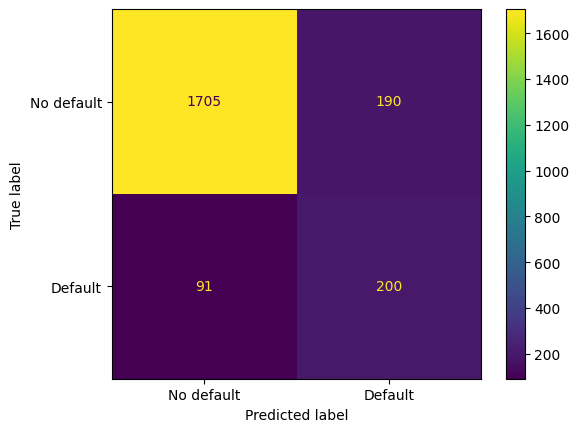

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rs_lgb, 
    X_test, 
    y_test, 
    display_labels=["No default", "Default"]
    )

In [16]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, 
    rs_lgb.predict(X_test), 
    target_names=["No default", "Default"]
    ))

              precision    recall  f1-score   support

  No default       0.95      0.90      0.92      1895
     Default       0.51      0.69      0.59       291

    accuracy                           0.87      2186
   macro avg       0.73      0.79      0.76      2186
weighted avg       0.89      0.87      0.88      2186



In [17]:
lgb_features = pd.DataFrame({
    'Feature': rs_lgb.best_estimator_.feature_names_in_,
    'Importance': rs_lgb.best_estimator_.feature_importances_
})

lgb_features.sort_values('Importance', ascending=False)

,Feature,Importance
2,vinculacion,2249
4,aportes,2052
13,curtotalingresos,1883
16,puntaje_data,1667
3,v_cuota,1473
7,edad,1280
14,curtotalegresos,989
1,plazo,964
11,ciudad,794
12,sexo,314


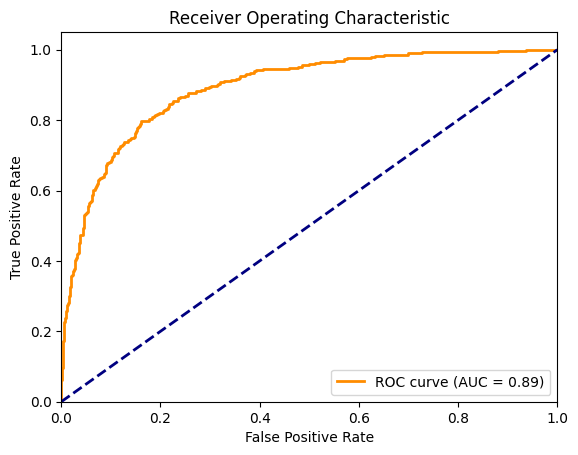

In [18]:
# Hacer curva ROC y calcular AUC
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_curve

y_pred_proba = rs_lgb.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

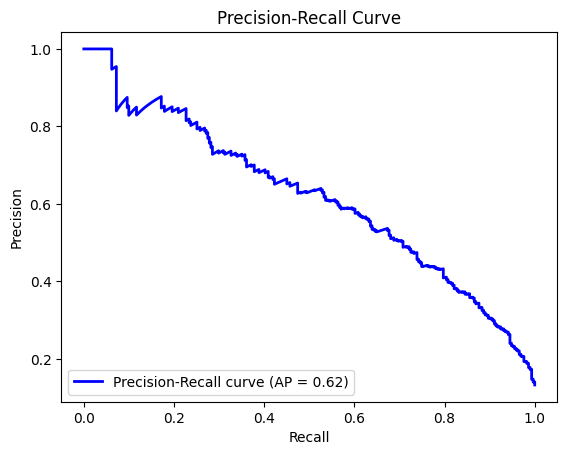

In [19]:
# Hacer curva Precision-Recall y calcular AUC
from sklearn.metrics import average_precision_score, precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
avg_precision = average_precision_score(y_test, y_pred_proba)

plt.figure()
plt.plot(recall, precision, color='blue', lw=2, label=f'Precision-Recall curve (AP = {avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

In [20]:
from sklearn.metrics import brier_score_loss, roc_auc_score

print("Prevalencia real de eventos:", y_test.mean())

probs_raw = rs_lgb.predict_proba(X_test)[:, 1]
print("AUC-ROC del modelo base:", roc_auc_score(y_test, probs_raw))
print("Brier Score del modelo base:", brier_score_loss(y_test, probs_raw))

Prevalencia real de eventos: 0.13311985361390669
AUC-ROC del modelo base: 0.89159208987297
Brier Score del modelo base: 0.09225920516600869


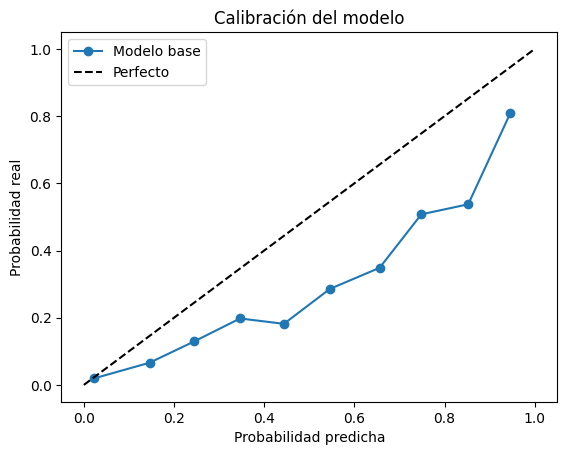

In [21]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, probs_raw, n_bins=10)

plt.plot(prob_pred, prob_true, "o-", label="Modelo base")
plt.plot([0, 1], [0, 1], "k--", label="Perfecto")
plt.xlabel("Probabilidad predicha")
plt.ylabel("Probabilidad real")
plt.title("Calibración del modelo")
plt.legend()
plt.show()

In [22]:
from sklearn.calibration import CalibratedClassifierCV

modelo_calibrado = CalibratedClassifierCV(
    estimator=rs_lgb.best_estimator_, 
    cv=5, 
    method='sigmoid'
    )

modelo_calibrado.fit(X_train, y_train)

probs_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

print("=== EVALUACIÓN DEL MODELO CALIBRADO ===")
print(f"Prevalencia real de eventos: {y_test.mean():.2%}")
print(f"ROC-AUC (Base):       {roc_auc_score(y_test, probs_raw):.4f}")
print(f"ROC-AUC (Calibrado):  {roc_auc_score(y_test, probs_cal):.4f}")
print(f"Brier Score (Base):      {brier_score_loss(y_test, probs_raw):.4f} (menor es mejor)")
print(f"Brier Score (Calibrado): {brier_score_loss(y_test, probs_cal):.4f} (menor es mejor)")

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

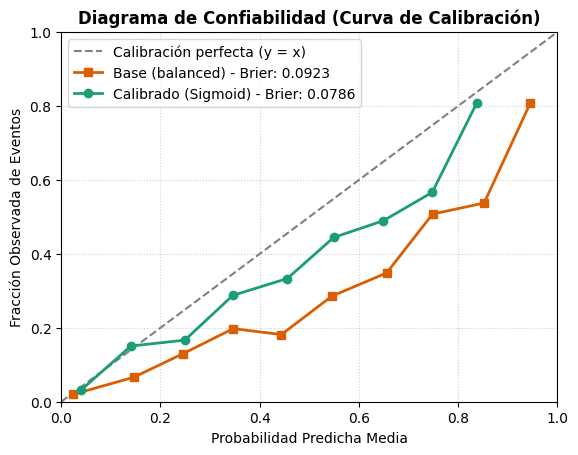

In [23]:
frac_pos_base, mean_pred_base = calibration_curve(y_test, probs_raw, n_bins=10, strategy='uniform')
frac_pos_cal, mean_pred_cal = calibration_curve(y_test, probs_cal, n_bins=10, strategy='uniform')

# 1. Diagrama de Confiabilidad

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración perfecta (y = x)')
plt.plot(mean_pred_base, frac_pos_base, marker='s', linewidth=2, color='#d95f02', 
             label=f'Base (balanced) - Brier: {brier_score_loss(y_test, probs_raw):.4f}')
plt.plot(mean_pred_cal, frac_pos_cal, marker='o', linewidth=2, color='#1b9e77', 
             label=f'Calibrado (Sigmoid) - Brier: {brier_score_loss(y_test, probs_cal):.4f}')

plt.title('Diagrama de Confiabilidad (Curva de Calibración)', fontweight='bold')
plt.xlabel('Probabilidad Predicha Media')
plt.ylabel('Fracción Observada de Eventos')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)

In [24]:
thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
eval_thresholds = []
    
for t in thresholds:
    preds_t = (probs_cal >= t).astype(int)
    rep = classification_report(y_test, preds_t, output_dict=True, zero_division=0)
    clase_default = rep["1.0"]
    eval_thresholds.append({
        "Umbral (tau)": t,
        "Precision (Clase 1)": clase_default["precision"],
        "Recall / Sensibilidad (Clase 1)": clase_default["recall"],
        "F1-Score (Clase 1)": clase_default["f1-score"],
        "Total Alertas Generadas": int(preds_t.sum())
    })

df_thresholds = pd.DataFrame(eval_thresholds)
print("=== COMPORTAMIENTO SEGÚN EL UMBRAL (MODELO CALIBRADO) ===")
print(df_thresholds.to_string(index=False))

=== COMPORTAMIENTO SEGÚN EL UMBRAL (MODELO CALIBRADO) ===
 Umbral (tau)  Precision (Clase 1)  Recall / Sensibilidad (Clase 1)  F1-Score (Clase 1)  Total Alertas Generadas
         0.05             0.287716                         0.917526            0.438064                      928
         0.10             0.374034                         0.831615            0.515991                      647
         0.20             0.451143                         0.745704            0.562176                      481
         0.30             0.511335                         0.697595            0.590116                      397
         0.40             0.561728                         0.625430            0.591870                      324
         0.50             0.601449                         0.570447            0.585538                      276
         0.60             0.639640                         0.487973            0.553606                      222
         0.70             0.682081    

In [25]:
# Modelo final con umbral de 0.6
preds_final = (probs_cal >= 0.50).astype(int)

print("=== EVALUACIÓN DEL MODELO FINAL ===")
print(classification_report(y_test, preds_final))

=== EVALUACIÓN DEL MODELO FINAL ===
              precision    recall  f1-score   support

         0.0       0.93      0.94      0.94      1895
         1.0       0.60      0.57      0.59       291

    accuracy                           0.89      2186
   macro avg       0.77      0.76      0.76      2186
weighted avg       0.89      0.89      0.89      2186



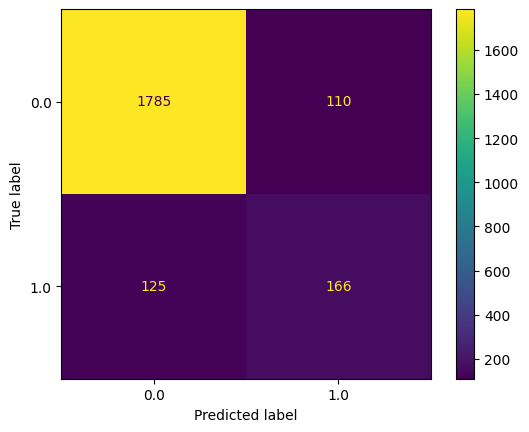

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, preds_final);

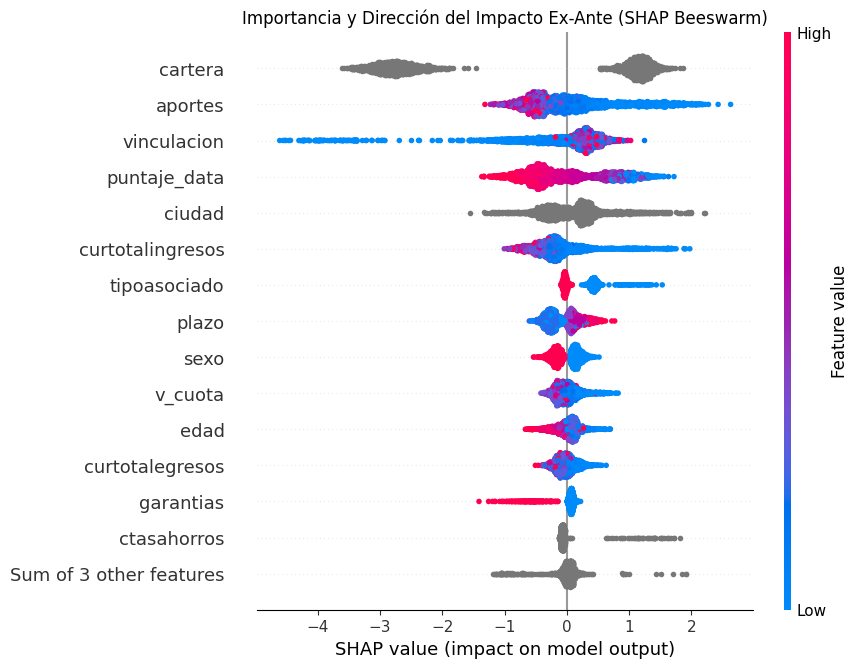

In [27]:
import shap

# 1. Extraer el modelo base óptimo (sin calibrar) de la búsqueda aleatoria
mejor_modelo_base = rs_lgb.best_estimator_

# 2. Inicializar el TreeExplainer de SHAP con el modelo base
# El TreeExplainer es el método exacto y optimizado para modelos basados en árboles como LightGBM
explainer = shap.TreeExplainer(mejor_modelo_base)

# 3. Calcular los valores SHAP. 
# Es fundamental calcularlos sobre X_test para evaluar cómo el modelo toma decisiones 
# sobre la cartera madura reciente (ex-ante) que no vio durante el entrenamiento.
shap_values = explainer(X_test)

# =====================================================================
# ANÁLISIS GLOBAL (Comportamiento general del modelo)
# =====================================================================
plt.figure(figsize=(10, 8))
plt.title("Importancia y Dirección del Impacto Ex-Ante (SHAP Beeswarm)")
# El beeswarm plot reemplaza al summary_plot antiguo, mostrando distribución y magnitud
shap.plots.beeswarm(shap_values, max_display=15)
plt.show()

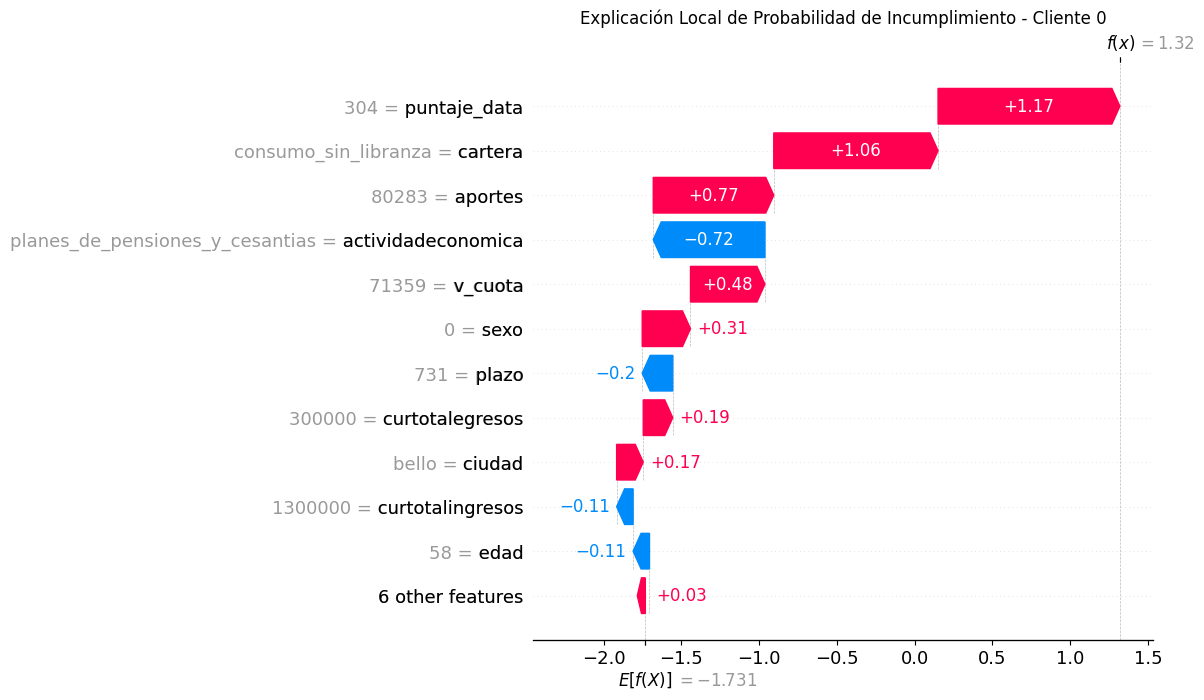

In [28]:
# =====================================================================
# ANÁLISIS LOCAL (Justificación de decisión para un cliente específico)
# =====================================================================
# Para el análisis individual, seleccionamos un cliente del test set. 
# Cambia 'indice_cliente' para auditar diferentes perfiles (ej. un falso positivo)
indice_cliente = 0 

plt.figure(figsize=(10, 6))
plt.title(f"Explicación Local de Probabilidad de Incumplimiento - Cliente {indice_cliente}")
# El waterfall plot detalla cómo cada variable empuja la predicción desde 
# el valor base (esperado) hasta la salida final del modelo (log-odds).
shap.plots.waterfall(shap_values[indice_cliente], max_display=12)
plt.show()

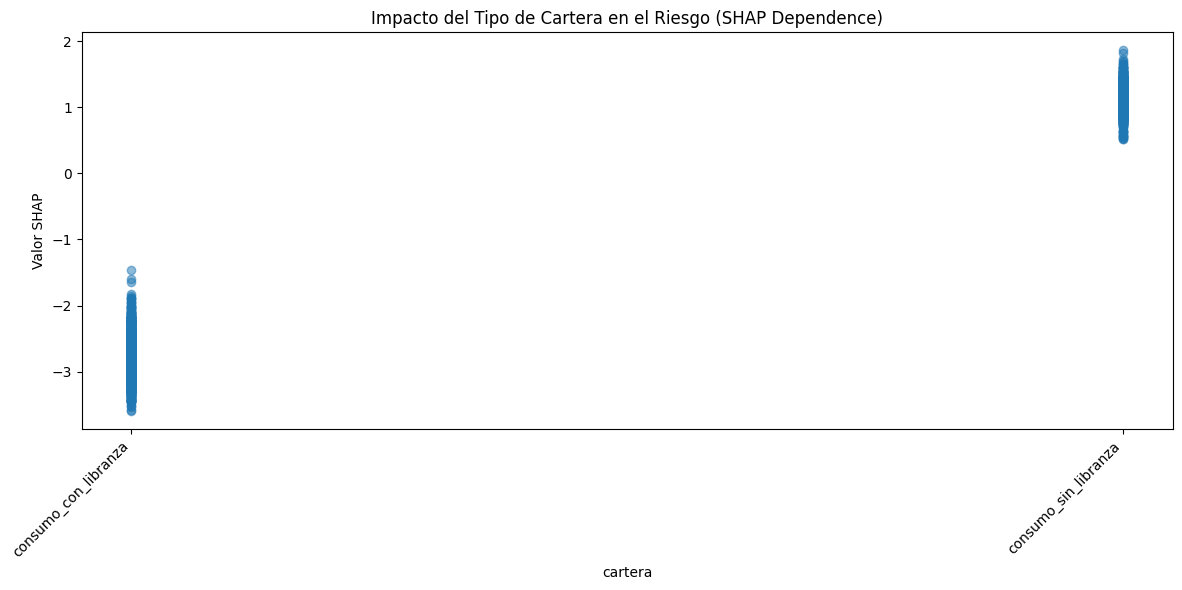

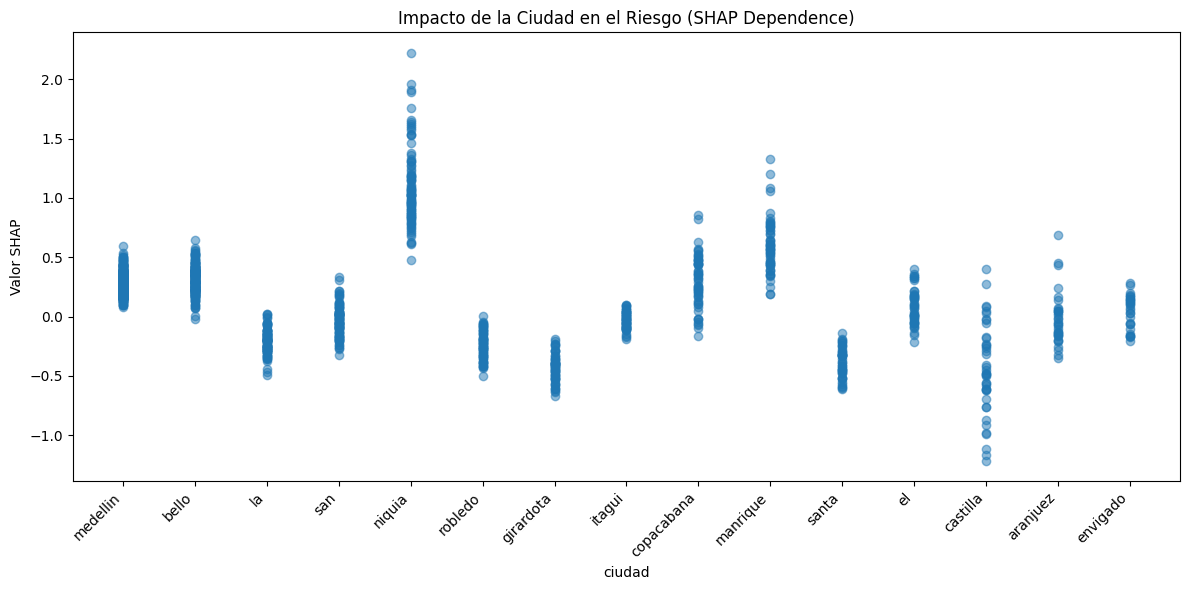

In [29]:
# =====================================================================
# GRÁFICO DE DEPENDENCIA PARCIAL SHAP (Para variables categóricas)
# =====================================================================

def plot_shap_categorical(feature, title, max_categories=15):
	values = X_test[feature].astype("string").fillna("Sin dato")
	categories = values.value_counts().head(max_categories).index
	mask = values.isin(categories)
	category_to_x = {category: i for i, category in enumerate(categories)}

	shap_feature = shap_values[:, feature].values
	x = values[mask].map(category_to_x).to_numpy()

	fig, ax = plt.subplots(figsize=(12, 6))
	ax.scatter(x, shap_feature[mask.to_numpy()], alpha=0.5)
	ax.set_xticks(range(len(categories)))
	ax.set_xticklabels(categories, rotation=45, ha="right")
	ax.set_xlabel(feature)
	ax.set_ylabel("Valor SHAP")
	ax.set_title(title)
	plt.tight_layout()
	plt.show()


# 1. Analizar la variable 'cartera'
plot_shap_categorical(
	"cartera",
	"Impacto del Tipo de Cartera en el Riesgo (SHAP Dependence)"
)


# 2. Analizar la variable 'ciudad' (se muestran las 15 categorías más frecuentes)
plot_shap_categorical(
	"ciudad",
	"Impacto de la Ciudad en el Riesgo (SHAP Dependence)"
)